<a href="https://colab.research.google.com/github/Abhishek1234563/-Robust-Multistatic-Target-Localization-/blob/main/rf_rotalo_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from scipy.stats import chi2

np.random.seed(42)

In [ ]:
M = 5
K = 200

TX = np.array([30.0, -15.0, 40.0])
TRUE_TARGET = np.array([-5.0, 5.0, 10.0])

RECEIVER_RADIUS = 50.0

OUTLIER_MAGNITUDE = 10
N_TRAIN = 400
MC_RUNS = 200

RF_TREES = 80
RF_ITERATIONS = 5

ALPHA = 0.05

rng = np.random.default_rng(42)

directions = rng.normal(size=(M, 3))
directions /= np.linalg.norm(directions, axis=1, keepdims=True)

RX = RECEIVER_RADIUS * directions

In [ ]:
def predicted_ranges(x):

    tx_distance = np.linalg.norm(x - TX)

    rx_distance = np.linalg.norm(x - RX, axis=1)

    return tx_distance + rx_distance

In [ ]:
def generate_data(target, noise_std, outlier_fraction, rng):

    true_ranges = predicted_ranges(target)

    noise = rng.normal(0, noise_std, (M, K))

    corrupted = rng.random((M, K)) < outlier_fraction

    outliers = rng.choice(
        [-OUTLIER_MAGNITUDE, OUTLIER_MAGNITUDE],
        size=(M, K)
    ) * corrupted

    measurements = (
        true_ranges[:, None] + noise + outliers
    )

    return measurements, corrupted

In [ ]:
def initial_position(D):

    median_ranges = np.median(D, axis=1)

    x = np.zeros(3)

    for _ in range(60):

        dt = x - TX
        a = max(np.linalg.norm(dt), 1e-8)

        dr = x[None, :] - RX
        b = np.maximum(np.linalg.norm(dr, axis=1), 1e-8)

        residual = median_ranges - (a + b)

        J = dt[None, :] / a + dr / b[:, None]

        step = np.linalg.solve(
            J.T @ J + 1e-5*np.eye(3),
            J.T @ residual
        )

        x = x + step

        if np.linalg.norm(step) < 1e-5:
            break

    return x

In [ ]:
def extract_features(D, x):

    residual = D - predicted_ranges(x)[:, None]

    scale = max(
        0.05,
        np.sqrt(np.mean(residual**2))
    )

    z = residual / scale

    receiver_mean = np.mean(z, axis=1)

    receiver_rms = np.sqrt(np.mean(z**2, axis=1))

    scene_mean = np.mean(z)

    scene_rms = np.sqrt(np.mean(z**2))

    features = np.column_stack([

        z.flatten(),

        np.abs(z).flatten(),

        np.repeat(receiver_mean, K),

        np.repeat(receiver_rms, K),

        np.full(M*K, scene_mean),

        np.full(M*K, scene_rms)

    ])

    return features

In [ ]:
X_train = []
y_train = []

train_rng = np.random.default_rng(43)

for _ in range(N_TRAIN):

    target = train_rng.uniform(-20, 20, 3)

    noise_std = np.sqrt(
        10**(train_rng.uniform(-3, 10)/10)
    )

    outlier_fraction = train_rng.uniform(0, 0.40)

    D, corrupted = generate_data(
        target,
        noise_std,
        outlier_fraction,
        train_rng
    )

    x0 = initial_position(D)

    features = extract_features(D, x0)

    X_train.append(features)

    labels = (~corrupted).astype(int).flatten()

    y_train.append(labels)


X_train = np.vstack(X_train)

y_train = np.concatenate(y_train)


rf_model = RandomForestClassifier(

    n_estimators=RF_TREES,

    max_depth=12,

    min_samples_leaf=5,

    class_weight="balanced",

    random_state=42,

    n_jobs=-1

)

rf_model.fit(X_train, y_train)

print("Random Forest training completed")

Random Forest training completed


In [ ]:
def position_update(D, mask, x):

    a = max(np.linalg.norm(x - TX), 1e-8)

    dr = x[None, :] - RX

    b = np.maximum(
        np.linalg.norm(dr, axis=1),
        1e-8
    )

    u = (x - TX) / a

    v = dr / b[:, None]

    h = a / b

    g = b / a

    terms = (

        D[:, :, None] *
        (u[None, None, :] + v[:, None, :])

        +

        (1 + g)[:, None, None] *
        TX[None, None, :]

        +

        (1 + h)[:, None, None] *
        RX[:, None, :]

    )

    numerator = np.sum(
        mask[:, :, None] * terms,
        axis=(0, 1)
    )

    denominator = np.sum(
        mask * (2 + h[:, None] + g[:, None])
    )

    if denominator < 1e-12:
        return x

    return numerator / denominator

In [ ]:
def fdr_mask(residual, sigma2):

    stats = (
        residual**2 / max(sigma2, 1e-8)
    ).flatten()

    n = len(stats)

    order = np.argsort(stats)[::-1]

    sorted_stats = stats[order]

    ranks = np.arange(1, n + 1)

    penalties = chi2.isf(
        ALPHA * ranks / n,
        df=1
    )

    tail = np.concatenate([
        np.cumsum(sorted_stats[::-1])[::-1],
        [0]
    ])

    penalty_sum = np.concatenate([
        [0],
        np.cumsum(penalties)
    ])

    costs = tail[:n] + penalty_sum[:n]

    rejected = np.argmin(costs)

    mask = np.ones(n)

    if rejected > 0:

        mask[order[:rejected]] = 0

    return mask.reshape(M, K), rejected, penalties


def run_rotalo(D):

    x = initial_position(D)

    mask = np.ones((M, K))

    previous_objective = None

    for _ in range(100):

        residual = D - predicted_ranges(x)[:, None]

        sigma2 = max(
            1e-6,
            np.sum(mask * residual**2) / (M*K)
        )

        x = position_update(D, mask, x)

        residual = D - predicted_ranges(x)[:, None]

        mask, rejected, penalties = fdr_mask(
            residual, sigma2
        )

        stats = residual**2 / sigma2

        objective = (
            M*K*np.log(sigma2)
            + np.sum(mask * stats)
            + np.sum(penalties[:rejected])
        )

        if previous_objective is not None:

            change = abs(
                objective - previous_objective
            ) / max(abs(previous_objective), 1e-12)

            if change < 1e-6:
                break

        previous_objective = objective

    return x

In [ ]:
def run_rf_rotalo(D):

    x = initial_position(D)

    mask = np.ones((M, K))

    clean_column = list(rf_model.classes_).index(1)

    for _ in range(RF_ITERATIONS):

        x = position_update(D, mask, x)

        features = extract_features(D, x)

        probabilities = rf_model.predict_proba(
            features
        )[:, clean_column]

        probabilities = probabilities.reshape(M, K)

        mask = (probabilities >= 0.5).astype(float)

        if np.sum(mask) == 0:
            mask[:] = 1

    return x

In [ ]:
def evaluate(noise_std, outlier_fraction, seed):

    local_rng = np.random.default_rng(seed)

    rotalo_errors = []

    rf_errors = []

    for _ in range(MC_RUNS):

        D, _ = generate_data(
            TRUE_TARGET,
            noise_std,
            outlier_fraction,
            local_rng
        )

        x_rotalo = run_rotalo(D)

        x_rf = run_rf_rotalo(D)

        rotalo_errors.append(
            np.linalg.norm(x_rotalo - TRUE_TARGET)
        )

        rf_errors.append(
            np.linalg.norm(x_rf - TRUE_TARGET)
        )

    rotalo_errors = np.array(rotalo_errors)

    rf_errors = np.array(rf_errors)

    return {

        "ROTALO_MSE": np.mean(rotalo_errors**2),

        "RF_MSE": np.mean(rf_errors**2),

        "ROTALO_RMSE": np.sqrt(
            np.mean(rotalo_errors**2)
        ),

        "RF_RMSE": np.sqrt(
            np.mean(rf_errors**2)
        )

    }

0% completed
5% completed
10% completed
15% completed
20% completed
25% completed
30% completed
35% completed
40% completed


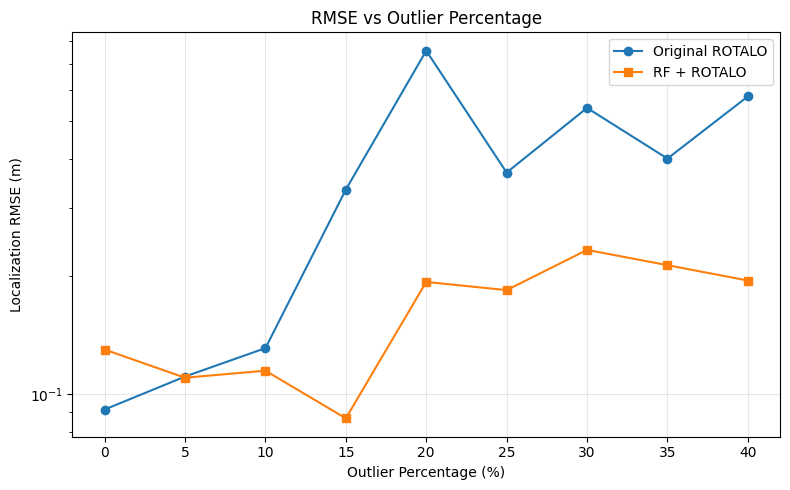

In [ ]:
# FAST Figure 2(b) - preliminary results

MC_RUNS = 10

outlier_percentages = np.arange(0, 41, 5)

results_outlier = []

for i, percentage in enumerate(outlier_percentages):

    result = evaluate(
        noise_std=1.0,
        outlier_fraction=percentage/100,
        seed=1000+i
    )

    results_outlier.append(result)

    print(f"{percentage}% completed")

df_outlier = pd.DataFrame(results_outlier)

df_outlier["Outlier_Percentage"] = outlier_percentages

plt.figure(figsize=(8,5))

plt.plot(
    outlier_percentages,
    df_outlier["ROTALO_RMSE"],
    'o-', label="Original ROTALO"
)

plt.plot(
    outlier_percentages,
    df_outlier["RF_RMSE"],
    's-', label="RF + ROTALO"
)

plt.xlabel("Outlier Percentage (%)")
plt.ylabel("Localization RMSE (m)")
plt.title("RMSE vs Outlier Percentage")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("Figure_2b.png", dpi=300)
plt.show()

-3 dB completed
-1 dB completed
1 dB completed
3 dB completed
5 dB completed
7 dB completed
9 dB completed


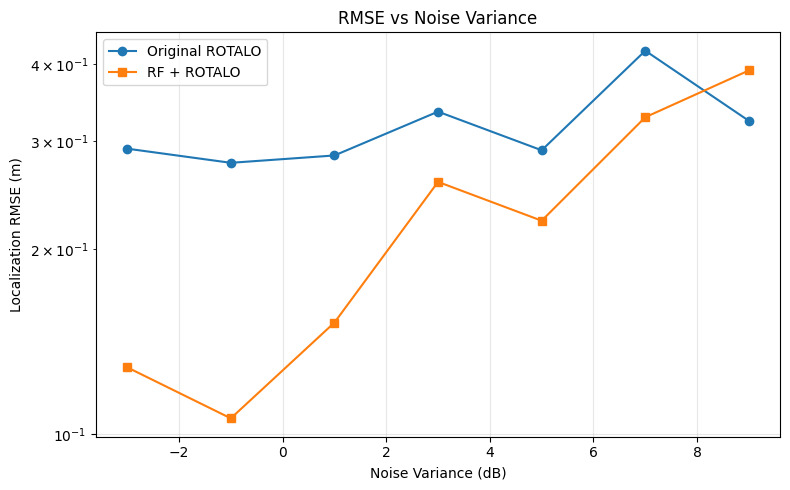

In [ ]:
# FAST Figure 2(c) - preliminary results

noise_db_levels = np.arange(-3, 11, 2)

results_noise = []

for i, db in enumerate(noise_db_levels):

    result = evaluate(
        noise_std=np.sqrt(10**(db/10)),
        outlier_fraction=0.10,
        seed=2000+i
    )

    results_noise.append(result)

    print(f"{db} dB completed")

df_noise = pd.DataFrame(results_noise)

df_noise["Noise_dB"] = noise_db_levels

plt.figure(figsize=(8,5))

plt.plot(
    noise_db_levels,
    df_noise["ROTALO_RMSE"],
    'o-', label="Original ROTALO"
)

plt.plot(
    noise_db_levels,
    df_noise["RF_RMSE"],
    's-', label="RF + ROTALO"
)

plt.xlabel("Noise Variance (dB)")
plt.ylabel("Localization RMSE (m)")
plt.title("RMSE vs Noise Variance")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("Figure_2c.png", dpi=300)
plt.show()

In [ ]:
with pd.ExcelWriter(
    "RF_ROTALO_Results.xlsx"
) as writer:

    df_outlier.to_excel(
        writer,
        sheet_name="Outlier_Comparison",
        index=False
    )

    df_noise.to_excel(
        writer,
        sheet_name="Noise_Comparison",
        index=False
    )

    pd.DataFrame({
        "Feature": [
            "Normalized residual",
            "Absolute normalized residual",
            "Receiver mean",
            "Receiver RMS",
            "Scene mean",
            "Scene RMS"
        ],
        "Importance": rf_model.feature_importances_
    }).to_excel(
        writer,
        sheet_name="Feature_Importance",
        index=False
    )

print("Excel results saved successfully!")

Excel results saved successfully!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
MC_RUNS = 200

noise_db_levels = np.arange(-3, 11, 1)
rf_noise_results = []

for j, db in enumerate(noise_db_levels):

    noise_variance = 10 ** (db / 10)
    noise_std = np.sqrt(noise_variance)

    errors = []
    rng = np.random.default_rng(SEED + 2000 + j)

    for _ in range(MC_RUNS):

        D, _ = generate_ranges(
            TRUE_TARGET,
            noise_std,
            0.10,       # 10% outliers
            rng
        )

        # RF-assisted ROTALO only
        estimated_position = run_rf(D, rf_model)

        error = np.linalg.norm(
            estimated_position - TRUE_TARGET
        )
        errors.append(error)

    mse = np.mean(np.array(errors) ** 2)
    rmse = np.sqrt(mse)

    rf_noise_results.append({
        "Noise_dB": db,
        "Noise_Variance_m2": noise_variance,
        "MSE_m2": mse,
        "RMSE_m": rmse
    })

    print(f"{db:+d} dB | RMSE: {rmse:.4f} m")


# Save results
rf_noise_df = pd.DataFrame(rf_noise_results)

# Plot
plt.figure(figsize=(8, 5))

plt.plot(
    rf_noise_df["Noise_dB"],
    rf_noise_df["RMSE_m"],
    marker="o",
    linewidth=2,
    label="Random Forest + ROTALO"
)

plt.xlabel(r"$10\log_{10}(\sigma^2)$ (dB)")
plt.ylabel("Localization RMSE (m)")
plt.title("RMSE vs Noise Variance — Random Forest-assisted ROTALO")

plt.yscale("log")
plt.xticks(noise_db_levels)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()

plt.savefig("RF_RMSE_vs_Noise.png", dpi=300)
plt.show()

rf_noise_df.to_excel("RF_Noise_Results.xlsx", index=False)

NameError: name 'generate_ranges' is not defined